In [1]:
%load_ext lab_black
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import polars as pl
from tqdm import tqdm
import os
import gc
import matplotlib.pyplot as plt
import warnings

import otto_recommender.utils as utils

warnings.filterwarnings("ignore")

pd.set_option("max_rows", 500)

%matplotlib inline

[12/11/22 19:22:11] WARNING  /media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto ]8;id=475427;file:///home/mikhail/anaconda3/lib/python3.7/warnings.py\warnings.py]8;;\:]8;id=637623;file:///home/mikhail/anaconda3/lib/python3.7/warnings.py#110\110]8;;\
                             /lib/python3.7/site-packages/IPython/extensions/autoreload.py:121:                    
                             DeprecationWarning: the imp module is deprecated in favour of                         
                             importlib; see the module's documentation for alternative uses                        
                               from imp import reload                                                              
                                                                                                                   

In [2]:
catalog.exists("sample_submission")

True

In [3]:
catalog.exists("df_train"), catalog.exists("df_test")

(True, True)

In [4]:
%%time

df_train = catalog.load("df_train")
df_test = catalog.load("df_test")

df_train.name = "df_train"
df_test.name = "df_test"

df_train = utils.make_date_stats(df_train)
df_test = utils.make_date_stats(df_test)

# df_train = pl.from_pandas(df_train)
# df_test = pl.from_pandas(df_test)

                    INFO     Loading data from 'df_train' (ParquetDataSet)...                   ]8;id=14377;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=155128;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py#344\344]8;;\

[12/11/22 19:22:28] INFO     Loading data from 'df_test' (ParquetDataSet)...                    ]8;id=511496;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py\data_catalog.py]8;;\:]8;id=61606;file:///media/mikhail/disk/ML/compet/kaggle/otto-recommender-system/venv_otto/lib/python3.7/site-packages/kedro/io/data_catalog.py#344\344]8;;\

CPU times: user 1min 55s, sys: 25.3 s, total: 2min 20s
Wall time: 1min 58s


In [5]:
df_train_n_session = (df_train.groupby("user")[["n_session"]].max() + 1).reset_index()
df_test_n_session = (df_test.groupby("user")[["n_session"]].max() + 1).reset_index()

In [6]:
df_train_n_session.corr(method="spearman")

,user,n_session
user,1.000000,-0.416181
n_session,-0.416181,1.000000


In [7]:
df_test_n_session.corr(method="spearman")

,user,n_session
user,1.000000,-0.122721
n_session,-0.122721,1.000000


In [8]:
df_train_n_session.head(10)

,user,n_session
0,0,48
1,1,11
2,2,5
3,3,23
4,4,4
5,5,3
6,6,13
7,7,6
8,8,1
9,9,3


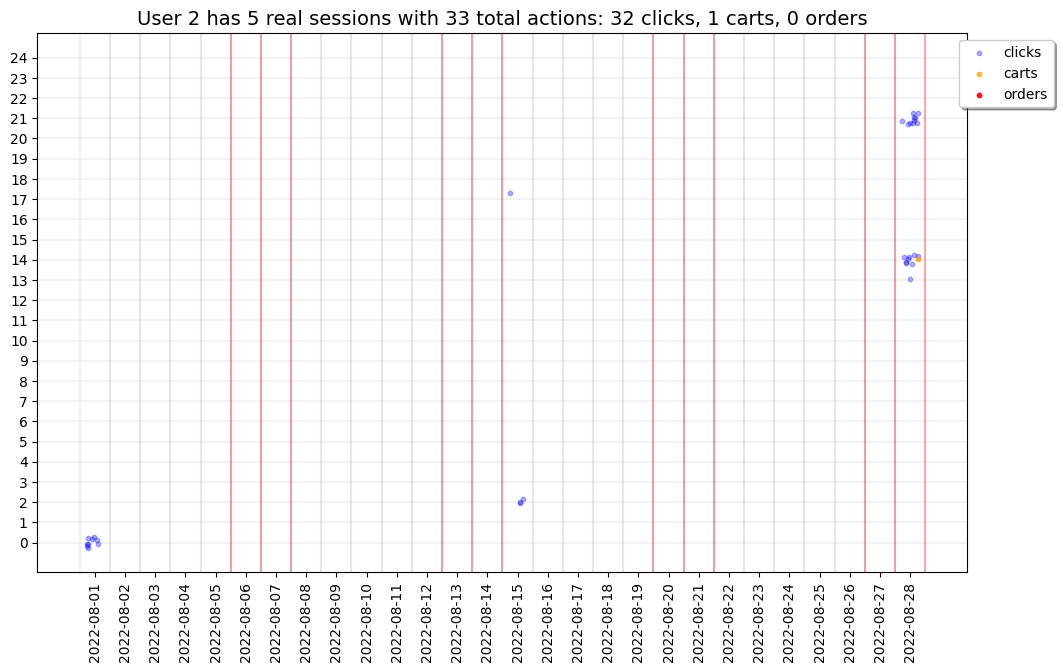

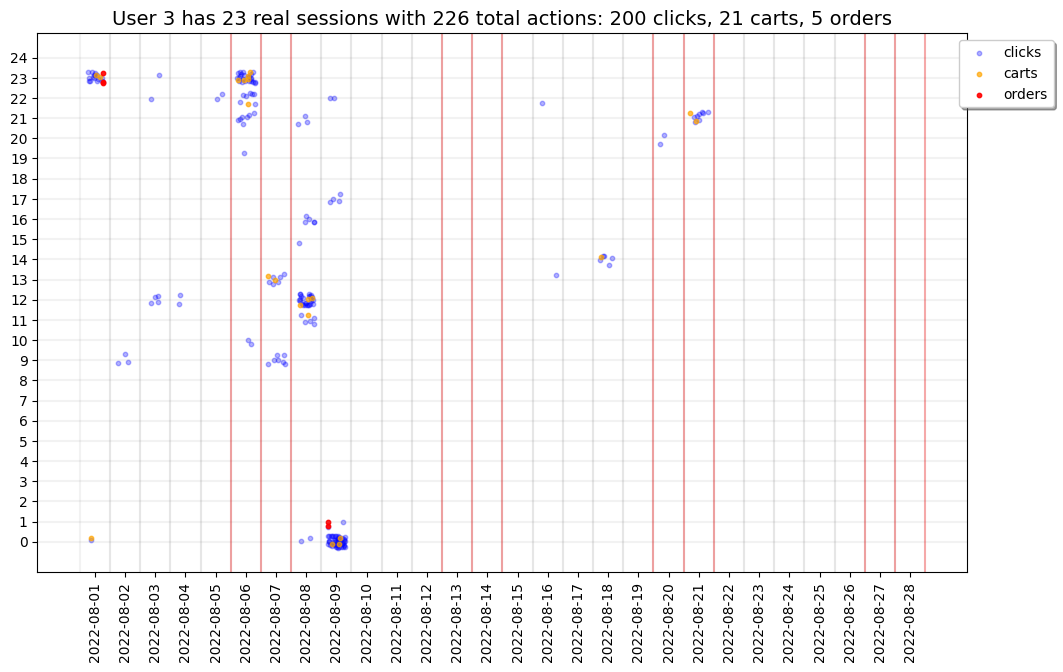

In [9]:
utils.plot_user_activity(list_users=[2, 3], df=df_train)

In [13]:
%%time

df_train = df_train.drop(['date', 'date_day', 'ts'], axis=1)
df_train = pl.from_pandas(df_train)

CPU times: user 9.74 s, sys: 2.35 s, total: 12.1 s
Wall time: 12.1 s


In [38]:
df_train.groupby(["n_week"]).count().sort("n_week", reverse=False)

n_week,count
i8,u32
31,53160878
32,55387191
33,55407112
34,52760915


In [47]:
df_train_ex = df_train.filter(pl.col("user") <= 10000)

In [48]:
%%time

dict_train = dict()
dict_answers = dict()
dict_val_len = dict()
dict_user = dict()
key = 1

for df_user in tqdm(df_train.groupby(["user"], maintain_order=True)):
    df_weeks_count = df_user.groupby(["n_week"]).count().sort("n_week", reverse=False)
    if len(df_weeks_count) <= 1:
        continue
    user = df_user["user"][0]
    for i in range(len(df_weeks_count["n_week"]) - 1):
        n_week_cur = df_weeks_count["n_week"][i]
        val_len = 34 - n_week_cur
        dict_train[key] = df_user.filter(pl.col("n_week") == n_week_cur)
        dict_answers[key] = df_user.filter(pl.col("n_week") > n_week_next)
        dict_val_len[key] = val_len
        dict_user[key] = user
        key += 1

12899779it [17:00:35, 210.66it/s]

CPU times: user 14d 14h 16min 31s, sys: 1d 19h 36min 58s, total: 16d 9h 53min 30s
Wall time: 17h 35s


In [55]:
%%time

for key in tqdm(dict_train):
    path = f"../data/02_intermediate/{key}/"
    if not os.path.exists(path):
        os.mkdir(path)
    filename_train = 'train.parquet'
    filename_answers = 'answers.parquet'
    dict_train[key].write_parquet(path + filename_train)
    dict_answers[key].write_parquet(path + filename_answers)

100%|██████████████████████████████| 9160020/9160020 [5:10:51<00:00, 491.12it/s]

CPU times: user 22h 13min 49s, sys: 5h 4min 19s, total: 1d 3h 18min 9s
Wall time: 5h 10min 51s


In [59]:
%%time

import json

with open("../data/02_intermediate/dict_val_len.json", 'w') as fp:
    json.dump(dict_val_len, fp)
    
with open("../data/02_intermediate/dict_user.json", 'w') as fp:
    json.dump(dict_user, fp)

CPU times: user 24.4 s, sys: 2.01 s, total: 26.4 s
Wall time: 26.4 s
